In [30]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [31]:
df=pd.read_csv("titanic.csv")

In [32]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
se = StandardScaler()                                         #Standard Scaling -- Works best with no outliers
se.fit_transform(df[['Age']])

array([[-0.53037664],
       [ 0.57183099],
       [-0.25482473],
       [ 0.36516706],
       [ 0.36516706],
       [        nan],
       [ 1.67403863],
       [-1.90813618],
       [-0.18593675],
       [-1.08148046],
       [-1.77036023],
       [ 1.94959054],
       [-0.6681526 ],
       [ 0.64071897],
       [-1.08148046],
       [ 1.74292661],
       [-1.90813618],
       [        nan],
       [ 0.08961515],
       [        nan],
       [ 0.36516706],
       [ 0.29627909],
       [-1.01259248],
       [-0.11704878],
       [-1.49480832],
       [ 0.57183099],
       [        nan],
       [-0.73704057],
       [        nan],
       [        nan],
       [ 0.70960695],
       [        nan],
       [        nan],
       [ 2.50069435],
       [-0.11704878],
       [ 0.8473829 ],
       [        nan],
       [-0.59926462],
       [-0.80592855],
       [-1.08148046],
       [ 0.70960695],
       [-0.18593675],
       [        nan],
       [-1.83924821],
       [-0.73704057],
       [  

In [34]:
df2 = pd.read_csv("scaling_with_outlier_dataset.csv")                         #loading dataset
df2

,Age,Income,Experience
0,22,30000,1
1,25,35000,2
2,28,40000,3
3,30,45000,4
4,32,50000,5
5,35,55000,6
6,38,60000,7
7,40,500000,8


In [35]:
from sklearn.preprocessing import RobustScaler                           #Robust Scaler -- Works best with outliers
rs = RobustScaler()

df2['Income']=rs.fit_transform(df2[['Income']])
print(df2['Income'])

from sklearn.preprocessing import MinMaxScaler                         #Min Max Scaler -- When you are aware of min and max values
mm = MinMaxScaler()
df2['Age']=mm.fit_transform(df2[['Age']])
print(df2['Age'])


0    -1.000000
1    -0.714286
2    -0.428571
3    -0.142857
4     0.142857
5     0.428571
6     0.714286
7    25.857143
Name: Income, dtype: float64
0    0.000000
1    0.166667
2    0.333333
3    0.444444
4    0.555556
5    0.722222
6    0.888889
7    1.000000
Name: Age, dtype: float64


In [36]:
#Outlier Handling

<Axes: ylabel='Income'>

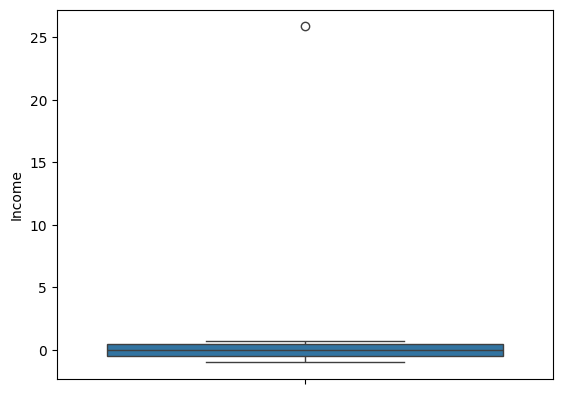

In [37]:
sns.boxplot(data=df2['Income'])                                #Outlier Visualization using BoxPlot
# sns.boxplot(data=df,x=df['Experience'])

<Axes: ylabel='Income'>

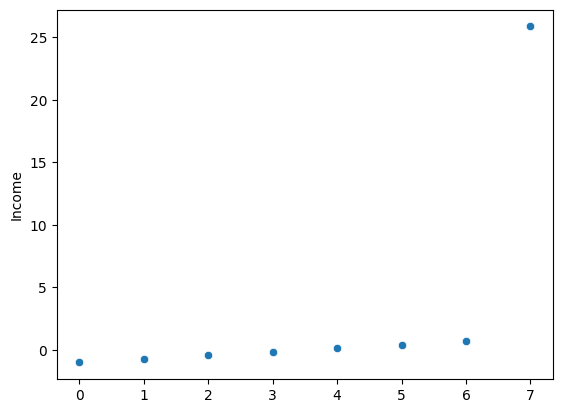

In [38]:
sns.scatterplot(data=df2['Income'])                                     #Outlier Visualization using ScatterPlot

<Axes: xlabel='Income', ylabel='Count'>

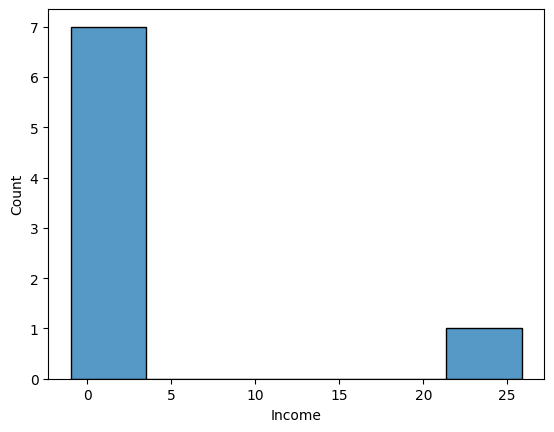

In [39]:
sns.histplot(data=df2['Income'])                                       #Outlier Visualization using histplot

In [ ]:
#OUTLIER DETECTION  -- Z Score , IQR Method , Percentile Method

In [40]:
                                                                        #Z Score

In [41]:
#iqr
#min , max anything beyond this line is OUTLIER
# min = q1 -1.5*IQR
# max = q3+1.5*IQR


#if d['Income']>Max - && D['Income]< Min -- OUTLIER
#IQR = Q3 -Q1



In [47]:
df2['Income']                                                               #IQR 
q1=df2['Income'].quantile(0.25)
q3=df2['Income'].quantile(0.75)

outlier = df2[(df2['Income']<q1)|(df2['Income']>q3)]
print(outlier)


        Age     Income  Experience
0  0.000000  -1.000000           1
1  0.166667  -0.714286           2
6  0.888889   0.714286           7
7  1.000000  25.857143           8


In [ ]:
df2['Income']                                                         #Percentile Method

l=df2['Income'].quantile(0.05)
u=df2['Income'].quantile(0.95)

outlier = df2[(df2['Income']<l)|(df2['Income']>u)]

print(outlier)





   Age     Income  Experience
0  0.0  -1.000000           1
7  1.0  25.857143           8
